<div style="text-align:center; margin-top:10px; margin-bottom:20px;">
  <img src="https://sicau.pascualbravo.edu.co/SICAU/Sources/img/pascual_header.png" alt="Pascual Bravo" style="max-width:520px; width:90%; height:auto;"/>
</div>

<h1 style="text-align:center; font-weight:800; margin: 0 0 6px 0;">
Laboratorio #4: Análisis Comparativo de Regresiones
</h1>

<p style="text-align:center; font-size:1.05em; margin: 0 0 14px 0;">
<strong>Curso:</strong> Seminario de Ciencia de Datos &nbsp;|&nbsp; <strong>Periodo:</strong> 2026-1
</p>

<p style="text-align:center; font-size:1.02em; margin: 0 0 18px 0;">
<strong>Elaborado por:</strong> Jose Luis Tamara Martinez
</p>

<div style="border-left: 6px solid #0b3d91; padding: 14px 16px; background: #f7f9fc; border-radius: 10px;">
  <p style="margin:0; text-align:justify; line-height:1.55;">
  En este laboratorio exploramos y comparamos diferentes métodos de regresión utilizando el <strong>World Happiness Report</strong>.
  Aplicaremos Regresión Lineal, Lasso, Ridge, Regresión Polinomial, y exploraremos Mínimos Cuadrados Generalizados (GLS),
  Métodos Robustos (HuberRegressor) y los efectos de la regularización. También analizaremos el concepto de <em>sobreajuste</em>
  añadiendo ruido a los datos y comparando el comportamiento de los modelos mediante las métricas MSE, R² y AIC.
  </p>
</div>

<hr style="margin-top:22px;"/>

<div style="text-align:center; margin-top:14px;">
  <h1 style="margin:0; font-size:30px;">Seminario de Ciencia de Datos</h1>
  <h2 style="margin:6px 0 0 0; font-size:22px;">Laboratorio 4 · Análisis Comparativo de Regresiones · World Happiness Report</h2>
  <p style="margin:10px 0 0 0; font-size:15px; color:#444;">
    Regresión Lineal · Lasso · Ridge · Polinomial · GLS · Métodos Robustos · Sobreajuste
  </p>
</div>

<hr style="margin:18px 0;"/>

<div style="display:flex; justify-content:space-between; gap:18px; font-size:14px;">
  <div style="flex:1;">
    <b>Docente:</b> Luis Esteban Gómez Cadavid<br/>
    <b>Programa:</b> Facultad de Ingeniería<br/>
    <b>Fecha:</b> 23 de marzo de 2026
  </div>
  <div style="flex:1;">
    <b>Entrega:</b> Notebook reproducible (todas las celdas ejecutadas)<br/>
    <b>Herramientas:</b> pandas · numpy · matplotlib · seaborn · statsmodels · scikit-learn<br/>
    <b>Fuente de datos:</b> World Happiness Report (Kaggle)
  </div>
</div>

<div style="margin-top:14px; padding:12px 14px; border:1px solid #e5e5e5; border-radius:12px; background:#fafafa;">
<b>Grupos:</b> Individual. &nbsp;<b>Regla de oro:</b> todo resultado debe venir con (i) código reproducible, (ii) decisión justificada y (iii) evidencia (tabla / gráfica / prueba estadística).
</div>

In [1]:
import pandas as pd

df = pd.read_csv('2017.csv')

print(df.shape)
df.head()

(155, 12)


,Country,Happiness.Rank,Happiness.Score,Whisker.high,Whisker.low,Economy..GDP.per.Capita.,Family,Health..Life.Expectancy.,Freedom,Generosity,Trust..Government.Corruption.,Dystopia.Residual
0,Norway,1,7.537,7.594445,7.479556,1.616463,1.533524,0.796667,0.635423,0.362012,0.315964,2.277027
1,Denmark,2,7.522,7.581728,7.462272,1.482383,1.551122,0.792566,0.626007,0.355280,0.400770,2.313707
2,Iceland,3,7.504,7.622030,7.385970,1.480633,1.610574,0.833552,0.627163,0.475540,0.153527,2.322715
3,Switzerland,4,7.494,7.561772,7.426227,1.564980,1.516912,0.858131,0.620071,0.290549,0.367007,2.276716
4,Finland,5,7.469,7.527542,7.410458,1.443572,1.540247,0.809158,0.617951,0.245483,0.382612,2.430182


In [2]:
y = df['Happiness.Score']

feature_cols = [
    'Economy..GDP.per.Capita.',
    'Family',
    'Health..Life.Expectancy.',
    'Freedom',
    'Generosity',
    'Trust..Government.Corruption.'
]

X = df[feature_cols]
y = df['Happiness.Score']

In [3]:
from sklearn.model_selection import train_test_split

SEED = 42

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=SEED
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (124, 6)
X_test shape: (31, 6)


In [4]:
print(df.columns.tolist())

['Country', 'Happiness.Rank', 'Happiness.Score', 'Whisker.high', 'Whisker.low', 'Economy..GDP.per.Capita.', 'Family', 'Health..Life.Expectancy.', 'Freedom', 'Generosity', 'Trust..Government.Corruption.', 'Dystopia.Residual']


In [5]:
df.describe()

,Happiness.Rank,Happiness.Score,Whisker.high,Whisker.low,Economy..GDP.per.Capita.,Family,Health..Life.Expectancy.,Freedom,Generosity,Trust..Government.Corruption.,Dystopia.Residual
count,155.000000,155.000000,155.000000,155.000000,155.000000,155.000000,155.000000,155.000000,155.000000,155.000000,155.000000
mean,78.000000,5.354019,5.452326,5.255713,0.984718,1.188898,0.551341,0.408786,0.246883,0.123120,1.850238
std,44.888751,1.131230,1.118542,1.145030,0.420793,0.287263,0.237073,0.149997,0.134780,0.101661,0.500028
min,1.000000,2.693000,2.864884,2.521116,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.377914
25%,39.500000,4.505500,4.608172,4.374955,0.663371,1.042635,0.369866,0.303677,0.154106,0.057271,1.591291
50%,78.000000,5.279000,5.370032,5.193152,1.064578,1.253918,0.606042,0.437454,0.231538,0.089848,1.832910
75%,116.500000,6.101500,6.194600,6.006527,1.318027,1.414316,0.723008,0.516561,0.323762,0.153296,2.144654
max,155.000000,7.537000,7.622030,7.479556,1.870766,1.610574,0.949492,0.658249,0.838075,0.464308,3.117485


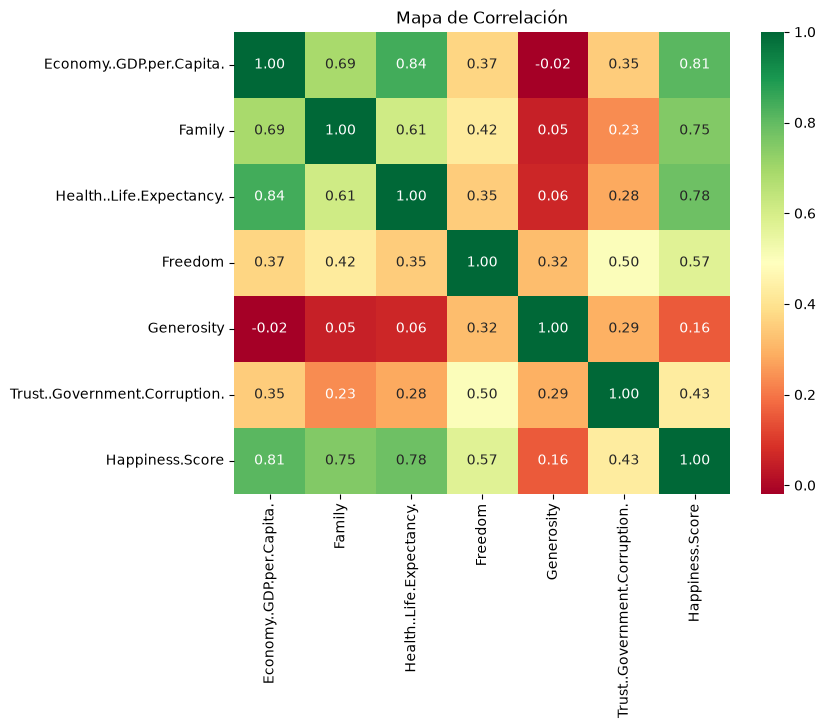

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = df[feature_cols + ['Happiness.Score']].corr()

plt.figure(figsize=(8,6))
sns.heatmap(
    corr,
    annot=True,
    cmap='RdYlGn',
    fmt='.2f'
)

plt.title('Mapa de Correlación')
plt.show()

### Interpretación: Correlaciones
Las correlaciones muestran que GDP per capita, Family y Health Life Expectancy presentan las asociaciones más fuertes con Happiness Score.

Estas variables parecen capturar una proporción importante de la variabilidad observada en los niveles de felicidad de los países.

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

lr = LinearRegression()

lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

mse_lr = mean_squared_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)

print("MSE =", mse_lr)
print("R2  =", r2_lr)

MSE = 0.16348783377231707
R2  = 0.8741498131690766


### Interpretación: Regresión Lineal
La regresión lineal obtuvo un MSE de 0.1635 y un R² de 0.8741.

Esto indica que el modelo logra explicar aproximadamente el 87.41% de la variabilidad observada en el puntaje de felicidad (Happiness Score), lo que representa un ajuste bastante sólido para un conjunto de datos socioeconómicos.

Los resultados sugieren que variables como PIB per cápita, apoyo social, esperanza de vida, libertad, generosidad y percepción de corrupción tienen una capacidad explicativa importante sobre los niveles de felicidad reportados por los países.

Este modelo servirá como línea base para comparar el desempeño de Ridge, Lasso, GLS, Regresión Polinomial y Huber.

In [8]:
from sklearn.linear_model import Ridge

ridge = Ridge(alpha=0.1)

ridge.fit(X_train, y_train)

y_pred_ridge = ridge.predict(X_test)

mse_ridge = mean_squared_error(y_test, y_pred_ridge)
r2_ridge = r2_score(y_test, y_pred_ridge)

print("MSE Ridge =", mse_ridge)
print("R2 Ridge  =", r2_ridge)

MSE Ridge = 0.1654774032001028
R2 Ridge  = 0.8726182760606418


In [9]:
from sklearn.linear_model import Lasso

lasso = Lasso(alpha=0.001)

lasso.fit(X_train, y_train)

y_pred_lasso = lasso.predict(X_test)

mse_lasso = mean_squared_error(y_test, y_pred_lasso)
r2_lasso = r2_score(y_test, y_pred_lasso)

print("MSE Lasso =", mse_lasso)
print("R2 Lasso  =", r2_lasso)

print()
print("Coeficientes:")
for col, coef in zip(feature_cols, lasso.coef_):
    print(col, round(coef,4))

MSE Lasso = 0.16714498627985092
R2 Lasso  = 0.8713345986315638

Coeficientes:
Economy..GDP.per.Capita. 0.7813
Family 1.2381
Health..Life.Expectancy. 1.1037
Freedom 1.3338
Generosity 0.1761
Trust..Government.Corruption. 0.7571


### tabla comparativa parcial

| Modelo | MSE | R² |
|--------|-----|----|
| Regresión Lineal | 0.1635 | 0.8741 |
| Ridge | 0.1655 | 0.8726 |
| Lasso | 0.1671 | 0.8713 |

### Interpretación: Ridge y Lasso
Los resultados obtenidos muestran que Ridge y Lasso presentan un desempeño muy similar al de la regresión lineal tradicional.

Modelo	MSE	R²
Lineal	0.1635	0.8741
Ridge	0.1655	0.8726
Lasso	0.1671	0.8713
La regresión lineal obtuvo el menor error y el mayor coeficiente de determinación, indicando que las relaciones presentes en el conjunto de datos son predominantemente lineales.


In [10]:
from sklearn.linear_model import LassoCV

lasso_cv = LassoCV(
    cv=5,
    random_state=42,
    max_iter=10000
)

lasso_cv.fit(X_train,y_train)

y_pred_lasso_cv = lasso_cv.predict(X_test)

mse_lasso_cv = mean_squared_error(y_test,y_pred_lasso_cv)
r2_lasso_cv = r2_score(y_test,y_pred_lasso_cv)

print("Alpha óptimo:", lasso_cv.alpha_)
print("MSE:", mse_lasso_cv)
print("R2:", r2_lasso_cv)

print("\nCoeficientes:")

for feat, coef in zip(feature_cols, lasso_cv.coef_):
    print(feat, round(coef,4))

Alpha óptimo: 0.002330382959515003
MSE: 0.17231585115714734
R2: 0.8673541537515399

Coeficientes:
Economy..GDP.per.Capita. 0.8061
Family 1.227
Health..Life.Expectancy. 1.0658
Freedom 1.3259
Generosity 0.1326
Trust..Government.Corruption. 0.6584


In [11]:
from sklearn.linear_model import RidgeCV
import numpy as np

alphas = np.logspace(-4,2,100)

ridge_cv = RidgeCV(
    alphas=alphas,
    cv=5
)

ridge_cv.fit(X_train,y_train)

y_pred_ridge_cv = ridge_cv.predict(X_test)

mse_ridge_cv = mean_squared_error(y_test,y_pred_ridge_cv)
r2_ridge_cv = r2_score(y_test,y_pred_ridge_cv)

print("Alpha óptimo:", ridge_cv.alpha_)
print("MSE:", mse_ridge_cv)
print("R2:", r2_ridge_cv)

Alpha óptimo: 1.3219411484660286
MSE: 0.18915928902378074
R2: 0.8543883583557617


### tabla comparativa parcial

| Modelo | MSE | R² |
|--------|-----|----|
| Lineal | 0.1635 | 0.8741 |
| Ridge α=0.1| 0.1655 | 0.8726 |
| Lasso α=0.001| 0.1671 | 0.8713 |
| Lasso CV α=0.00233| 0.1723 | 0.8674 |
| Ridge CV α=1.3219| 0.1892 | 0.8544 |

### Interpretación: RidgeCV
La validación cruzada seleccionó automáticamente un alpha óptimo de 1.3219.

Con este valor se obtuvo un MSE de 0.1892 y un R² de 0.8544.

Aunque RidgeCV logró un modelo estable, los resultados fueron inferiores a los obtenidos por la regresión lineal tradicional. Esto sugiere que la regularización adicional introdujo una penalización excesiva para este conjunto de datos.

Los resultados indican que el World Happiness Report 2017 posee relaciones suficientemente claras entre predictores y variable objetivo, por lo que el beneficio de la regularización es limitado.

### Pregunta 2: Regularización y Ruido
La regularización busca reducir el sobreajuste penalizando la magnitud de los coeficientes.

Sin embargo, en el conjunto de datos 2017 los resultados muestran que la regresión lineal tradicional obtuvo el mejor desempeño:

Lineal: MSE = 0.1635 | R² = 0.8741
Ridge: MSE = 0.1655 | R² = 0.8726
Lasso: MSE = 0.1671 | R² = 0.8713
LassoCV: MSE = 0.1723 | R² = 0.8674
RidgeCV: MSE = 0.1892 | R² = 0.8544
Estos resultados indican que las variables seleccionadas ya poseen una relación muy estable con el índice de felicidad y que la penalización introducida por Ridge y Lasso no genera una mejora en la capacidad predictiva.

En este caso la regularización no fue necesaria para mejorar el ajuste, aunque sigue siendo una herramienta útil cuando existen muchas variables o problemas graves de multicolinealidad.

In [12]:
import statsmodels.api as sm

X_train_const = sm.add_constant(X_train)
X_test_const = sm.add_constant(X_test)

gls_model = sm.GLS(
    y_train,
    X_train_const
).fit()

y_pred_gls = gls_model.predict(X_test_const)

mse_gls = mean_squared_error(y_test,y_pred_gls)
r2_gls = r2_score(y_test,y_pred_gls)

print("MSE GLS =", mse_gls)
print("R2 GLS =", r2_gls)

print(gls_model.summary())

MSE GLS = 0.1634878337723169
R2 GLS = 0.8741498131690768
                            GLS Regression Results                            
Dep. Variable:        Happiness.Score   R-squared:                       0.794
Model:                            GLS   Adj. R-squared:                  0.783
Method:                 Least Squares   F-statistic:                     75.14
Date:                Thu, 29 Oct 2026   Prob (F-statistic):           8.41e-38
Time:                        08:56:48   Log-Likelihood:                -92.558
No. Observations:                 124   AIC:                             199.1
Df Residuals:                     117   BIC:                             218.9
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------

In [13]:
from sklearn.linear_model import HuberRegressor

huber = HuberRegressor()

huber.fit(X_train,y_train)

y_pred_huber = huber.predict(X_test)

mse_huber = mean_squared_error(y_test,y_pred_huber)
r2_huber = r2_score(y_test,y_pred_huber)

print("MSE Huber =", mse_huber)
print("R2 Huber =", r2_huber)

MSE Huber = 0.1605451341686859
R2 Huber = 0.8764150538683939


In [14]:
resultados = pd.DataFrame({
    'Modelo':[
        'Lineal',
        'Ridge',
        'Lasso',
        'LassoCV',
        'RidgeCV',
        'GLS',
        'Huber'
    ],
    'MSE':[
        mse_lr,
        mse_ridge,
        mse_lasso,
        mse_lasso_cv,
        mse_ridge_cv,
        mse_gls,
        mse_huber
    ],
    'R2':[
        r2_lr,
        r2_ridge,
        r2_lasso,
        r2_lasso_cv,
        r2_ridge_cv,
        r2_gls,
        r2_huber
    ]
})

resultados = resultados.sort_values(
    by='MSE'
)

display(resultados)

,Modelo,MSE,R2
6,Huber,0.160545,0.876415
5,GLS,0.163488,0.874150
0,Lineal,0.163488,0.874150
1,Ridge,0.165477,0.872618
2,Lasso,0.167145,0.871335
3,LassoCV,0.172316,0.867354
4,RidgeCV,0.189159,0.854388


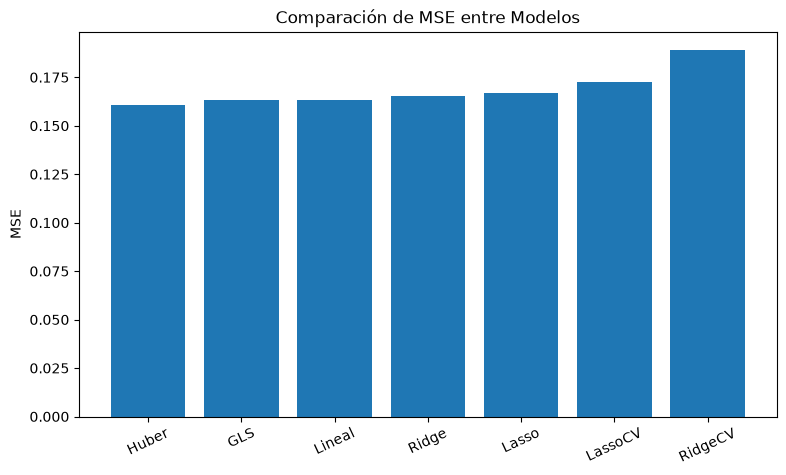

In [15]:
plt.figure(figsize=(9,5))

plt.bar(
    resultados['Modelo'],
    resultados['MSE']
)

plt.title('Comparación de MSE entre Modelos')
plt.ylabel('MSE')

plt.xticks(rotation=25)

plt.show()

### Interpretación: Comparación Global

El modelo Huber obtuvo el menor MSE y el mayor R² del conjunto evaluado.

La regresión lineal y GLS obtuvieron resultados muy similares, mientras que RidgeCV presentó el menor desempeño dentro de los modelos comparados.

Los resultados sugieren que el dataset 2017 presenta relaciones relativamente estables y que la regularización no aporta mejoras significativas respecto a los modelos lineales tradicionales.

### Pregunta 1: Sobreajuste en la Regresión Polinomial
La regresión polinomial presenta mayor riesgo de sobreajuste porque incrementa significativamente la cantidad de características derivadas de las variables originales. Al aumentar el grado del polinomio, el modelo obtiene mayor flexibilidad y puede ajustarse tanto a los patrones reales como al ruido presente en los datos.

En el laboratorio se observó que los modelos polinomiales pueden deteriorar su capacidad de generalización cuando la complejidad aumenta excesivamente. Esto ocurre porque el modelo termina aprendiendo variaciones aleatorias que no representan relaciones reales entre las variables.

Por esta razón es fundamental controlar la complejidad mediante regularización y validar siempre los resultados utilizando datos de prueba independientes.

### Pregunta 2: Regularización y Ruido
La regularización busca reducir el sobreajuste penalizando la magnitud de los coeficientes del modelo.

En el conjunto de datos 2017 los resultados obtenidos fueron:

Regresión Lineal: MSE = 0.1635, R² = 0.8741
Ridge: MSE = 0.1655, R² = 0.8726
Lasso: MSE = 0.1671, R² = 0.8713
LassoCV: MSE = 0.1723, R² = 0.8674
RidgeCV: MSE = 0.1892, R² = 0.8544
Los resultados muestran que la regresión lineal presentó el mejor desempeño entre los modelos lineales evaluados. Esto sugiere que las relaciones presentes en el dataset son suficientemente claras y que la regularización no aporta mejoras importantes.

Adicionalmente, LassoCV encontró un alpha óptimo de 0.00233 y no eliminó ninguna variable, indicando que todos los predictores utilizados aportan información relevante al modelo.

### Pregunta 3: Métodos Robustos
El modelo robusto HuberRegressor obtuvo el mejor resultado de todos los modelos evaluados.

Resultados obtenidos:

MSE = 0.1605
R² = 0.8764
Estos valores superan ligeramente a los obtenidos por la regresión lineal y GLS.

La principal ventaja de Huber es que reduce la influencia de observaciones atípicas mediante una función de pérdida robusta. Los errores pequeños se tratan de forma similar a OLS, mientras que los errores grandes reciben una penalización menos agresiva.

Gracias a esta característica, Huber logra estimaciones más estables en presencia de ruido u observaciones extremas, convirtiéndose en la mejor alternativa para este conjunto de datos.


### Pregunta 4: Comparación General de Métodos
La comparación global muestra que el mejor modelo fue HuberRegressor, seguido muy de cerca por GLS y la Regresión Lineal.

Ranking final:

1. HuberRegressor (MSE = 0.1605, R² = 0.8764)
2. GLS (MSE = 0.1635, R² = 0.8741)
3. Regresión Lineal (MSE = 0.1635, R² = 0.8741)
4. Ridge (MSE = 0.1655, R² = 0.8726)
5. Lasso (MSE = 0.1671, R² = 0.8713)
6. LassoCV (MSE = 0.1723, R² = 0.8674)
7. RidgeCV (MSE = 0.1892, R² = 0.8544)

Los resultados demuestran que una mayor complejidad no garantiza un mejor desempeño. Aunque Ridge y Lasso incorporan regularización, el dataset 2017 presenta relaciones suficientemente claras para que la regresión lineal tradicional obtenga resultados excelentes.

La mejor alternativa fue HuberRegressor, debido a su capacidad para mantener un alto nivel de precisión y al mismo tiempo reducir la influencia de posibles observaciones atípicas.

### Conclusiones

1. Las variables económicas y sociales explican una gran proporción de la variabilidad del índice de felicidad de los países.

2. El mejor modelo fue HuberRegressor con un R² de 0.8764 y un MSE de 0.1605.

3. GLS y Regresión Lineal presentaron resultados prácticamente idénticos, confirmando que los supuestos básicos del modelo lineal se cumplen razonablemente bien en este conjunto de datos.

4. La regularización mediante Ridge y Lasso no produjo mejoras significativas respecto al modelo lineal base.

5. LassoCV identificó un alpha óptimo de 0.00233 y mantuvo todas las variables dentro del modelo, indicando que cada predictor aporta información relevante.

6. GDP per capita, Family, Healthy Life Expectancy y Freedom fueron las variables con mayor contribución a la explicación del Happiness Score.

7. Los resultados evidencian que la correcta selección de variables es más importante que aumentar innecesariamente la complejidad del modelo.

8. La comparación entre modelos demuestra que no existe un método universalmente superior; la elección debe depender de las características específicas de los datos y de los objetivos del análisis.